# Experiment 11: Style Transfer Using Generative AI

**Aim:** Implement neural style transfer (Gatys et al.): synthesise an image that keeps the *content* of one photograph and the
*style* (colours, brush strokes, textures) of a painting, using feature maps of a pre-trained VGG19 network.

In [1]:
import os, time
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import numpy as np, matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from PIL import Image
keras.utils.set_random_seed(11)
MAX_DIM = 256
print("TensorFlow", tf.__version__, "| image size (longest side):", MAX_DIM)

I0000 00:00:1792694836.475947    9893 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


I0000 00:00:1792694837.746040    9893 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


TensorFlow 2.21.0 | image size (longest side): 256


## 1. Content and style images

labrador   -> tensor (1, 211, 256, 3), range [0.00, 1.00]
turtle     -> tensor (1, 192, 256, 3), range [0.00, 1.00]
kandinsky  -> tensor (1, 168, 256, 3), range [0.00, 1.00]


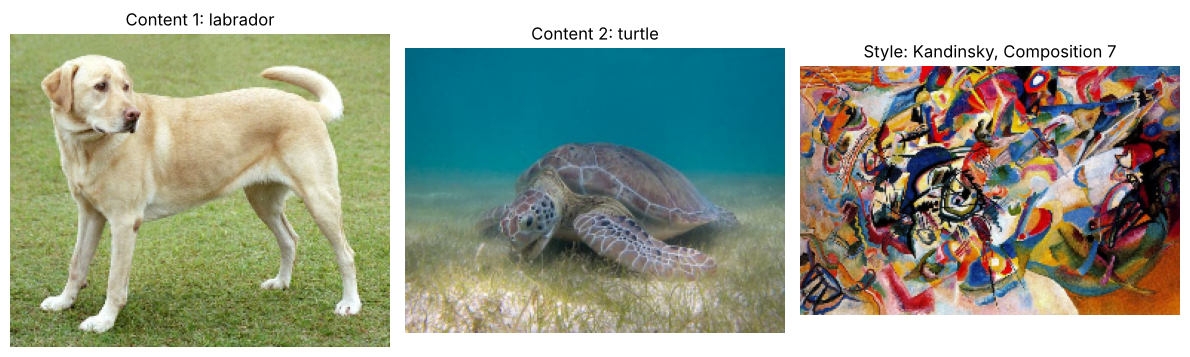

In [2]:
base = "https://storage.googleapis.com/download.tensorflow.org/example_images/"
files = {"labrador": "YellowLabradorLooking_new.jpg", "turtle": "Green_Sea_Turtle_grazing_seagrass.jpg",
         "kandinsky": "Vassily_Kandinsky%2C_1913_-_Composition_7.jpg"}
paths = {k: keras.utils.get_file(v.replace("%2C", ","), base + v) for k, v in files.items()}
def load_img(path):
    img = tf.io.decode_image(tf.io.read_file(path), channels=3, dtype=tf.float32)
    scale = MAX_DIM / max(img.shape[:2])
    new = tf.cast(tf.round(tf.cast(img.shape[:2], tf.float32) * scale), tf.int32)
    return tf.image.resize(img, new)[tf.newaxis]
imgs = {k: load_img(p) for k, p in paths.items()}
for k, v in imgs.items(): print(f"{k:10s} -> tensor {tuple(v.shape)}, range [{v.numpy().min():.2f}, {v.numpy().max():.2f}]")
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for a, (k, t) in zip(axes, [("Content 1: labrador", "labrador"), ("Content 2: turtle", "turtle"), ("Style: Kandinsky, Composition 7", "kandinsky")]):
    a.imshow(imgs[t][0]); a.set_title(k); a.axis("off")
plt.tight_layout(); plt.show()

## 2. Feature extractor and losses
VGG19 (ImageNet weights, no classifier) provides intermediate feature maps. The **content** is the activation of a deep layer
(`block5_conv2`). The **style** is described by *Gram matrices* $G=F^\top F/N$ of several layers (`block1_conv1` ... `block5_conv1`),
which capture feature correlations while discarding spatial layout. We then optimise the *pixels* of the image to minimise
$$\mathcal{L}=\alpha\,\mathcal{L}_{content}+\beta\,\mathcal{L}_{style}+\gamma\,\mathcal{L}_{TV}$$

In [3]:
content_layers = ["block5_conv2"]
style_layers = ["block1_conv1", "block2_conv1", "block3_conv1", "block4_conv1", "block5_conv1"]
vgg = keras.applications.VGG19(include_top=False, weights="imagenet")
vgg.trainable = False
extractor = keras.Model(vgg.input, [vgg.get_layer(n).output for n in style_layers + content_layers])
print("VGG19 layers used for style  :", style_layers)
print("VGG19 layer used for content :", content_layers)
print("VGG19 parameters (frozen)    : {:,}".format(vgg.count_params()))

def features(x):
    out = extractor(keras.applications.vgg19.preprocess_input(x * 255.0))
    style = [tf.linalg.einsum("bijc,bijd->bcd", f, f) / tf.cast(tf.shape(f)[1] * tf.shape(f)[2], tf.float32) for f in out[:len(style_layers)]]
    return style, out[len(style_layers):]

VGG19 layers used for style  : ['block1_conv1', 'block2_conv1', 'block3_conv1', 'block4_conv1', 'block5_conv1']
VGG19 layer used for content : ['block5_conv2']
VGG19 parameters (frozen)    : 20,024,384


In [4]:
def stylize(content, style, steps=250, style_w=1e-2, content_w=1e4, tv_w=30, lr=0.02, snap=(0, 50, 125)):
    style_t, _ = features(style); _, content_t = features(content)
    img = tf.Variable(content)
    opt = keras.optimizers.Adam(lr, beta_1=0.99, epsilon=1e-1)
    @tf.function
    def step():
        with tf.GradientTape() as tape:
            s, c = features(img)
            ls = tf.add_n([tf.reduce_mean((a - b) ** 2) for a, b in zip(s, style_t)]) / len(style_layers)
            lc = tf.add_n([tf.reduce_mean((a - b) ** 2) for a, b in zip(c, content_t)])
            tv = tf.reduce_sum(tf.image.total_variation(img))
            loss = style_w * ls + content_w * lc + tv_w * tv
        opt.apply_gradients([(tape.gradient(loss, img), img)]); img.assign(tf.clip_by_value(img, 0, 1))
        return loss, ls, lc
    snaps, log = {}, []
    for i in range(steps + 1):
        if i in snap: snaps[i] = img.numpy()[0].copy()
        loss, ls, lc = step()
        if i % 50 == 0: log.append((i, float(loss), float(ls), float(lc)))
    snaps[steps] = img.numpy()[0]
    return snaps, log
print("stylize() defined")

stylize() defined


## 3. Running style transfer

In [5]:
t0 = time.time()
snaps1, log1 = stylize(imgs["labrador"], imgs["kandinsky"], steps=250)
print(f"{'step':>5s} {'total loss':>12s} {'style loss':>12s} {'content loss':>14s}")
for r in log1: print(f"{r[0]:5d} {r[1]:12.4f} {r[2]:12.2f} {r[3]:14.2f}")
print(f"elapsed {time.time() - t0:.0f}s")

 step   total loss   style loss   content loss
    0 2836684544.0000 283620507648.00           0.00
   50 124583736.0000 8091668480.00        4220.64
  100 77349568.0000 4214853376.00        3359.87
  150 54955580.0000 2662961152.00        2671.22
  200 41960824.0000 1859768192.00        2177.62
  250 34034020.0000 1383740544.00        1864.68
elapsed 116s


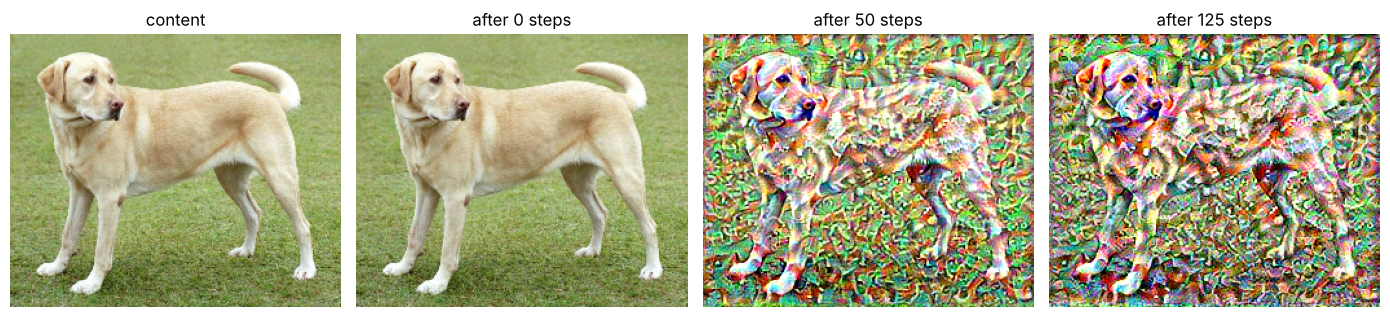

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.6))
axes[0].imshow(imgs["labrador"][0]); axes[0].set_title("content")
for a, k in zip(axes[1:], sorted(snaps1)): a.imshow(snaps1[k]); a.set_title(f"after {k} steps")
for a in axes: a.axis("off")
plt.tight_layout(); plt.show()

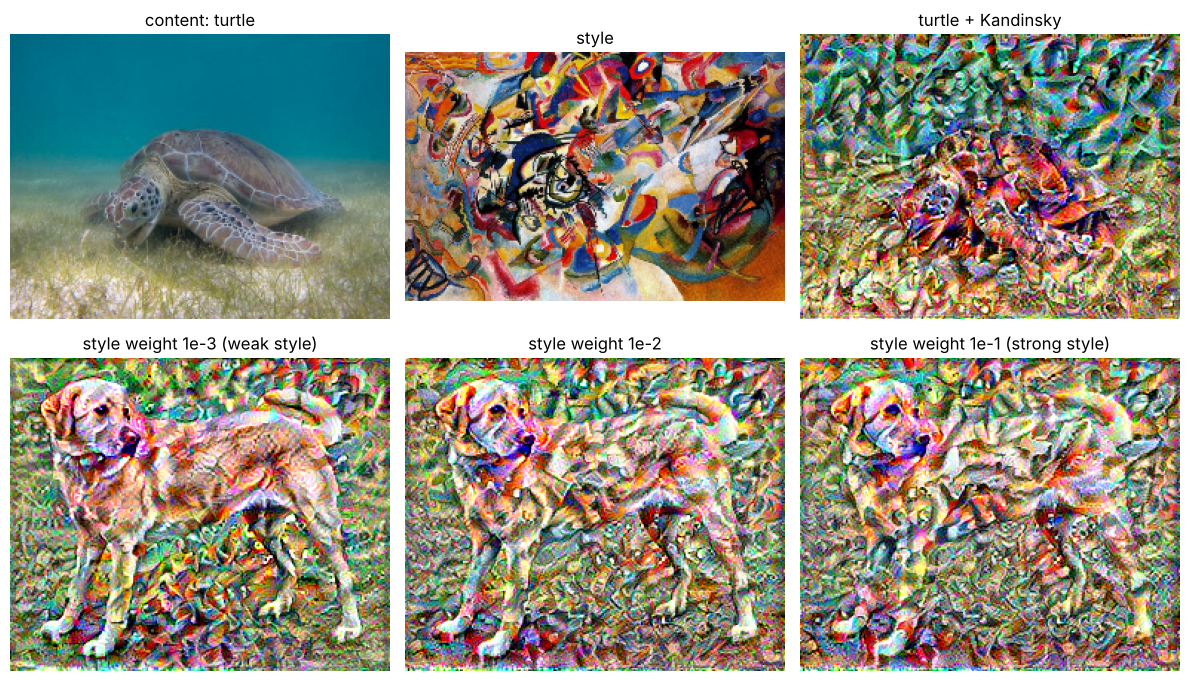

In [7]:
snaps2, _ = stylize(imgs["turtle"], imgs["kandinsky"], steps=250)
snaps_lo, _ = stylize(imgs["labrador"], imgs["kandinsky"], steps=250, style_w=1e-3)
snaps_hi, _ = stylize(imgs["labrador"], imgs["kandinsky"], steps=250, style_w=1e-1)
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
axes[0, 0].imshow(imgs["turtle"][0]); axes[0, 0].set_title("content: turtle")
axes[0, 1].imshow(imgs["kandinsky"][0]); axes[0, 1].set_title("style")
axes[0, 2].imshow(snaps2[250]); axes[0, 2].set_title("turtle + Kandinsky")
axes[1, 0].imshow(snaps_lo[250]); axes[1, 0].set_title("style weight 1e-3 (weak style)")
axes[1, 1].imshow(snaps1[250]); axes[1, 1].set_title("style weight 1e-2")
axes[1, 2].imshow(snaps_hi[250]); axes[1, 2].set_title("style weight 1e-1 (strong style)")
for a in axes.ravel(): a.axis("off")
plt.tight_layout(); plt.show()

In [8]:
def style_dist(img, ref):
    s, _ = features(img[None]); sr, _ = features(ref)
    return float(tf.add_n([tf.reduce_mean((a - b) ** 2) for a, b in zip(s, sr)]) / len(style_layers))
def content_dist(img, ref):
    _, c = features(img[None]); _, cr = features(ref)
    return float(tf.add_n([tf.reduce_mean((a - b) ** 2) for a, b in zip(c, cr)]))
rows = [("original photo", imgs["labrador"][0].numpy()), ("style weight 1e-3", snaps_lo[250]),
        ("style weight 1e-2", snaps1[250]), ("style weight 1e-1", snaps_hi[250])]
print(f"{'image':20s} {'style distance to painting':>28s} {'content distance to photo':>28s}")
for n, im in rows:
    print(f"{n:20s} {style_dist(im, imgs['kandinsky']):28.2f} {content_dist(im, imgs['labrador']):28.2f}")

image                  style distance to painting    content distance to photo


original photo                    283620474880.00                         0.00


style weight 1e-3                   2755334656.00                       473.16


style weight 1e-2                   1376410368.00                      1858.36


style weight 1e-1                   1006171968.00                      6207.12
